# 🔬 Melanoma Detection Deep Learning Model

**Prepared by:**
- Serena Zaarour - 202310507
- Nour Mina - 202311852

## **1. Setup & Imports**

### 1.1 Install Dependencies

In [ ]:
# not pre-installed on colab
  # kaggle: used for kaggle key authentication to be able to download the datasets
  # kagglehub: module that handles extracting the datasets and downloading them locally
!pip install -q kaggle kagglehub

### 1.2 Import Libraries

In [ ]:
# section 1
import warnings
import tensorflow as tf
from tensorflow.keras import mixed_precision
from google.colab import drive

# section 2
import kagglehub
import os
from google.colab import userdata
from pathlib import Path

# section 3
import pandas as pd
import hashlib

# section 4
from sklearn.model_selection import GroupShuffleSplit

# section 5
import numpy as np
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# section 6
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras import Model

# section 8
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint, ReduceLROnPlateau

# section 11
from sklearn.metrics import roc_auc_score, roc_curve, classification_report, confusion_matrix
import seaborn as sns

# section 12
from sklearn.metrics import recall_score, precision_score, f1_score

# section 15
import json

import shutil, math
from sklearn.utils import class_weight

### 1.3 Checking Configurations

In [ ]:
# mainly to silent deprecation warnings
warnings.filterwarnings('ignore')
# checks TensorFlow version
print('TF version:', tf.__version__)
# checks if colab is using GPU (if this line prints an empty list [], this means we're training on CPU)
print('GPU:', tf.config.list_physical_devices('GPU'))

# Mixed precision: ~2× speedup on T4 GPU
  # normally numbers in a neural network are stored as float32
  # float16 uses half the memory & is faster on GPUs
  # so by using 'mixed_precision':
    # - float16 for speed in most calculations (compute type)
    # - float32 for accuracy in critical places like when storing weights (variable type)
mixed_precision.set_global_policy('mixed_float16')
print('Compute dtype:', mixed_precision.global_policy().compute_dtype)
print('Variable dtype:', mixed_precision.global_policy().variable_dtype)

TF version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Compute dtype: float16
Variable dtype: float32


### 1.4 Mount Google Drive

In [ ]:
# to connect colab to our drive
drive.mount('/content/drive')

Mounted at /content/drive


### 1.5 Define Paths, Image Size, Batch Size & Seed

In [ ]:
DRIVE_BASE   = Path('/content/drive/MyDrive/melanoma_project')
# /content/raw is the colab temporary data storage directory
RAW_DIR      = Path('/content/raw')

# HAM10000 + ISIC 2020 combined
MERGED_DIR   = DRIVE_BASE / 'merged'
# train/val/test splits
SPLIT_DIR    = DRIVE_BASE / 'data'
# model weights & metadata(summary of the model)
MODEL_DIR    = DRIVE_BASE / 'models'

# iterates on the folders to create them
for p in [RAW_DIR, MERGED_DIR, SPLIT_DIR, MODEL_DIR]:
    p.mkdir(parents=True, exist_ok=True)

# EfficientNetB0's native input size
IMG_SIZE   = (224, 224)

# when training a neural network we don't feed it all 50000 images at once
# we give them to the model in 'batches' (here 64 images)
# after the model is fed all the data in batches → it is called an epoch
BATCH_SIZE = 64

# for consistent results
SEED       = 42
tf.keras.utils.set_random_seed(SEED)

print('Paths ready.')

Paths ready.


## **2. Downloading datasets from Kaggle**

### Authenticate with Kaggle & Download both Datasets

In [ ]:
# os is used to set environment variables in colab, one of them is 'KAGGLE_API_TOKEN'
# KAGGLE_API_TOKEN is a SPECIFIC name kagglehub looks for to authenticate download requests
# userdata gets the stored key in colab and injects it in KAGGLE_API_TOKEN to be used by kagglehub
os.environ["KAGGLE_API_TOKEN"] = userdata.get('KAGGLE_KEY')

# .dataset_download() function downloads the datasets from kaggle on kaggle cache & returns the path where saved on kaggle
# the path is mainly messy this is why we create for it a symbolic link
path_ham = kagglehub.dataset_download("kmader/skin-cancer-mnist-ham10000")
path_isic = kagglehub.dataset_download("sumaiyabinteshahid/isic-challenge-dataset-2020")
# terminal command to create the symbolic links
!ln -sfn {path_ham} /content/ham10000_data
!ln -sfn {path_isic} /content/isic2020_data

print(f"HAM10000 images are here: {path_ham}")
print(f"ISIC 2020 images are here: {path_isic}")

# wraps string returned by kagglehub into a path object to be able to navigate files easier (using .rglob(), .glob()..)
HAM_DIR  = Path(path_ham)
ISIC_DIR = Path(path_isic)

Using Colab cache for faster access to the 'skin-cancer-mnist-ham10000' dataset.
Using Colab cache for faster access to the 'isic-challenge-dataset-2020' dataset.
HAM10000 images are here: /kaggle/input/skin-cancer-mnist-ham10000
ISIC 2020 images are here: /kaggle/input/isic-challenge-dataset-2020


## **3. Merge, Binary-Label & Deduplicate**





### 3.1 Prepare HAM10000 Dataset

In [ ]:
# searching for the metadata of the HAM10000 dataset
  # it is used to map each image to its label and other useful information
# next() is used to grab the first result generated by .rglob()
ham_meta_path = next(HAM_DIR.rglob('HAM10000_metadata.csv'))
# reading the content of the metadata csv file
ham_meta = pd.read_csv(ham_meta_path)

print('HAM metadata shape:', ham_meta.shape)
print()
# printing the target(dx) variable values
print(ham_meta['dx'].value_counts())
print()

# creating a new column in metadata dataframe 'label'
  # if dx == mel → label == 1
  # if dx != mel → label == 0
ham_meta['label'] = (ham_meta['dx'] == 'mel').astype(int)

ham_img_dirs = list(HAM_DIR.rglob('HAM10000_images_part_*')) # returns: [Path('/kaggle/input/ham10000/HAM10000_images_part_1'), Path('/kaggle/input/ham10000/HAM10000_images_part_2')]
ham_img_map  = {} # creating a dictionnary to map each image name to its path
for d in ham_img_dirs:
    for f in d.glob('*.jpg'):
        # f.stem stores only the filename
        ham_img_map[f.stem] = f # returns: {'ISIC_0024306': Path('.../part_1/ISIC_0024306.jpg'), 'ISIC_0024307': Path('.../part_1/ISIC_0024307.jpg'), 'ISIC_0024308': Path('.../part_1/ISIC_0024308.jpg'), }

# for standardization when we merge HAM10000 with ISIC2020 (HAM doesnt have a patient_id)
# NOTE: it's okay to have duplicate patient_id, our unique identifier is the image_id
ham_meta['patient_id'] = ham_meta['lesion_id']
ham_meta['source'] = 'HAM'

ham_meta['filepath'] = ham_meta['image_id'].map(ham_img_map) # maps each image_id to the file path saved in dict
ham_meta = ham_meta[['image_id', 'label', 'patient_id', 'filepath', 'source']].copy()
ham_meta = ham_meta.dropna(subset=['filepath']) # drops the row without a filepath mapped to its image_id

ham_meta.rename(columns={'image_id': 'image_name'}, inplace=True)

print(f'HAM images found: {len(ham_meta)}')
print()
print(ham_meta['label'].value_counts())

HAM metadata shape: (10015, 7)

dx
nv       6705
mel      1113
bkl      1099
bcc       514
akiec     327
vasc      142
df        115
Name: count, dtype: int64

HAM images found: 10015

label
0    8902
1    1113
Name: count, dtype: int64


### 3.2 Prepare ISIC2020 Dataset

In [ ]:
isic_meta_path = next(ISIC_DIR.rglob('ISIC_2020_Train_Metadata.csv'))

isic_meta = pd.read_csv(isic_meta_path)

print('ISIC 2020 metadata shape:', isic_meta.shape)
print()
print(isic_meta.columns.tolist())
print()
print(isic_meta['target'].value_counts())

isic_img_dir = next(ISIC_DIR.rglob('train'))

isic_img_map = {}
for f in isic_img_dir.glob('*.jpg'):
    isic_img_map[f.stem] = f

isic_meta['filepath'] = isic_meta['image_name'].map(isic_img_map)
isic_meta['label']    = isic_meta['target'] # to standardize the labels to match HAM
isic_meta['source']   = 'ISIC2020'

isic_meta = isic_meta[['image_name', 'label', 'patient_id', 'filepath', 'source']].copy()
isic_meta = isic_meta.dropna(subset=['filepath'])

print(f'ISIC images found: {len(isic_meta)}')
print(isic_meta['label'].value_counts())

ISIC 2020 metadata shape: (33126, 9)

['image_name', 'patient_id', 'lesion_id', 'sex', 'age_approx', 'anatom_site_general_challenge', 'diagnosis', 'benign_malignant', 'target']

target
0    32542
1      584
Name: count, dtype: int64
ISIC images found: 33126
label
0    32542
1      584
Name: count, dtype: int64


### 3.3 Merging Datasets

In [ ]:
merged = pd.concat([ham_meta, isic_meta], ignore_index=True)
print(f'Total before dedup: {len(merged)}')
print()
print(merged['label'].value_counts())
print()
print("Dataframe Head: ")
print(merged.head())

Total before dedup: 43141

label
0    41444
1     1697
Name: count, dtype: int64

Dataframe Head: 
     image_name  label   patient_id  \
0  ISIC_0027419      0  HAM_0000118   
1  ISIC_0025030      0  HAM_0000118   
2  ISIC_0026769      0  HAM_0002730   
3  ISIC_0025661      0  HAM_0002730   
4  ISIC_0031633      0  HAM_0001466   

                                            filepath source  
0  /kaggle/input/skin-cancer-mnist-ham10000/HAM10...    HAM  
1  /kaggle/input/skin-cancer-mnist-ham10000/HAM10...    HAM  
2  /kaggle/input/skin-cancer-mnist-ham10000/HAM10...    HAM  
3  /kaggle/input/skin-cancer-mnist-ham10000/HAM10...    HAM  
4  /kaggle/input/skin-cancer-mnist-ham10000/HAM10...    HAM  


### 3.4 MD5 Hash Deduplication

In [ ]:
# why hashing is used? to detect image duplication in the file content not in filename

# create the hashing function
def f_md5(path):
    with open(path, 'rb') as f: # r:read, b:binary mode
        return hashlib.md5(f.read()).hexdigest() # .hexdigest() converts the hashed result into an
                                                  # alpha-numerical string

hashes = []
for path in merged['filepath']:
    hashes.append(f_md5(str(path)))
# created a column named hash that has the hash of each image
merged['hash'] = hashes

before = len(merged)

# drop rows with duplicate hashes, keeping the first occurrence
merged = merged.drop_duplicates(subset='hash', keep='first')

print(f'Removed {before - len(merged)} exact duplicates → {len(merged)} images remain')
print()
print(merged['label'].value_counts())

Removed 435 exact duplicates → 42706 images remain

label
0    41012
1     1694
Name: count, dtype: int64


### 3.5 Balance the Dataset

In [ ]:
# NOTE: keeping the model target balance as is would make the model say benign for everything and
  # still get 97% accuracy. This is because benign labels makeup 97% of the dataset (42000 out of 43000)
  # & the model would be useless at predicting melanomas. Solution: reduce nb of benign images to a
  # reasonable ratio (20%/80%) → closer to real life scenarios.

# creates new mel & benign dataframes based on a condition
mel    = merged[merged['label'] == 1]
benign = merged[merged['label'] == 0]

n_mel    = len(mel)
# this will create a 80% 20% ratio
n_benign = int(n_mel * 4)

# SEED makes the sampling consistent with every run
# n=n_benign means to take n samples from the benign dataset
benign_sampled  = benign.sample(n=n_benign, random_state=SEED)

# .sample() used to shuffle the dataset or else the melanoma samples would be at the top & benign after them
balanced = pd.concat([mel, benign_sampled], ignore_index=True).sample(frac=1, random_state=SEED)

print(f'Dataset after sampling: {len(balanced)} images')
print()
print(balanced['label'].value_counts())

Dataset after sampling: 8470 images

label
0    6776
1    1694
Name: count, dtype: int64


## **4. Patient-Level train / val / test split (on patient_id)**

In [ ]:
# NOTE: we used GroupShuffleSplit to keep the lesions belonging to the same patient_id in the same split:
# we do this because the images belonging to the same patient are taken from different angles so they are technically the same lesion
# so if 1 is in test and 1 is in train, the model would memorize the output instead of predicting since they're the same

# 15% test
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=SEED)
trainval_idx, test_idx = next(gss_test.split(balanced, balanced['label'], groups=balanced['patient_id']))
trainval = balanced.iloc[trainval_idx].reset_index(drop=True) # .iloc() selects rows by their idx
test_df  = balanced.iloc[test_idx].reset_index(drop=True)

# ~15% val from remaining 85%:
  # we want val to be 15% of the full dataset
  # trainval dataset is 85% of the full dataset
  # calulations: fraction that gives us 15%
    # x * 0.85 = 0.15
    # x = 0.15/0.85
    # x = 0.176 → this is the % of the split size in trainval
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.176, random_state=SEED)
train_idx, val_idx = next(gss_val.split(trainval, trainval['label'], groups=trainval['patient_id']))
train_df = trainval.iloc[train_idx].reset_index(drop=True)
val_df   = trainval.iloc[val_idx].reset_index(drop=True)

# now we have 3 dataframes: train_df, val_df, test_df
print(f'Train : {len(train_df)} (70%)')
print(f'Val   : {len(val_df)} (15%)')
print(f'Test  : {len(test_df)} (15%)')

Train : 5826 (70%)
Val   : 1376 (15%)
Test  : 1268 (15%)


## **5. Build `tf.data` input pipeline**

In [ ]:
# Augmentation Pipeline:
  # this teaches the model that a melanoma is still a melanoma, regardless of the angle of the photo.
  # at each epoch the model is seeing the same images but rotated & flipped
  # this prevents the AI from memorizing and teaches it to recognize the pattern of
    # the disease regardless of how the photo was taken
data_augmentation = tf.keras.Sequential([
    layers.RandomFlip('horizontal_and_vertical'), # flip left/right/up/down
    layers.RandomRotation(factor=0.2), # rotates images ±72° (0.2 → 20% of 360°)
    layers.RandomZoom(height_factor=0.15, width_factor=0.15), # zoom in/out up to 15%
    layers.RandomTranslation(0.1, 0.1), # randomly shifts image up/down/left/right by 10%
    layers.RandomContrast(0.15), # randomly adjusts contrast by up to 15%
    layers.RandomBrightness(0.15), # randomly adjust brightness by up to 15%
], name='augmentation')

def apply_augmentation(images, labels):
    augmented_images = data_augmentation(images, training=True)
    return augmented_images, labels

# tensor: n dimensional array of numbers
# in our case:
  # our images are 224x224
  # we use RGB
# so our tensor is a 3D tensor of shape 224x224x3 stored in a numerical float32 format
def decode_image(filepath, label):
    img_bytes = tf.io.read_file(filepath) # read bytes from file
    img = tf.image.decode_jpeg(img_bytes, channels=3) # decodes these bytes into a tensor (RGB)
    img = tf.image.resize(img, IMG_SIZE, method='bilinear') # resizing image
    img = tf.cast(img, tf.float32) # converts pixel vals from int to float32 since EfficientNet expects float16
    return img, label # → returns Tensor + Label

# this function takes a list of file paths and turn them into a high-speed stream of images that the
# AI learns from
def make_dataset(df, training=False):
    paths  = df['filepath'].astype(str).values
    labels = df['label'].astype('float32').values
    # creates a basic "Dataset" object, which is like a digital checklist of every image the AI needs to see
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    # if all the Melanoma images were at the beginning, the AI might just learn the order of the list
      # instead of learning what cancer actually looks like.
    # we "reshuffle" every time the AI finishes the whole ds so it never sees the same order twice
    # since sometimes we can't put all training data on RAM, we can make a mixing bowl (buffer_size)
      # the computer randomly picks one image out of that "mixing bowl" to send to the AI
      # as soon as one image is picked, the computer immediately grabs the next image from your original
        #list and puts it into the bowl to keep it full
    if training:
        ds = ds.shuffle(buffer_size=min(len(df), 4096), seed=SEED, reshuffle_each_iteration=True)

    # decode_image() opens the files, resizes them to 224x224 and turns them to numbers
    # tf.data.AUTOTUNE → tells the computer to use all its available "brains" (CPU cores)
      # to open images as fast as possible so the training doesn't slow down
    ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    # batching the data into BATCH_SIZE=64
    # keeps remainder images means to keep the last batch that isnt exactly 64 images (it's less)
    ds = ds.batch(BATCH_SIZE, drop_remainder=False)

    if training:
        # tells the computer to use all its available "brains" (CPU cores) to process
          # many images at the exact same time
        ds = ds.map(apply_augmentation, num_parallel_calls=tf.data.AUTOTUNE)
    # in deep learning, the "Brain" (GPU) is often faster than the "Hands" (the hard drive)
    # prefetching ensures the AI never has to sit idle waiting for the next photo to be loaded from the disk
    ds = ds.prefetch(tf.data.AUTOTUNE)
    return ds


train_ds = make_dataset(train_df, training=True)
val_ds   = make_dataset(val_df,   training=False)
test_ds  = make_dataset(test_df,  training=False)

print('Datasets built!')
print('Train batches:', tf.data.experimental.cardinality(train_ds).numpy())
print('Val batches  :', tf.data.experimental.cardinality(val_ds).numpy())
print('Test batches :', tf.data.experimental.cardinality(test_ds).numpy())

Datasets built!
Train batches: 92
Val batches  : 22
Test batches : 20


Batch shape: (64, 224, 224, 3) dtype: <dtype: 'float16'>
Pixel range: [0.0, 255.0]
Label distribution in batch: [53 11]


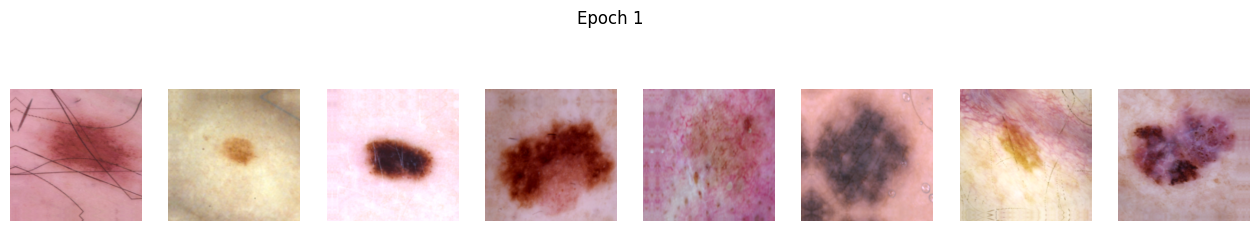

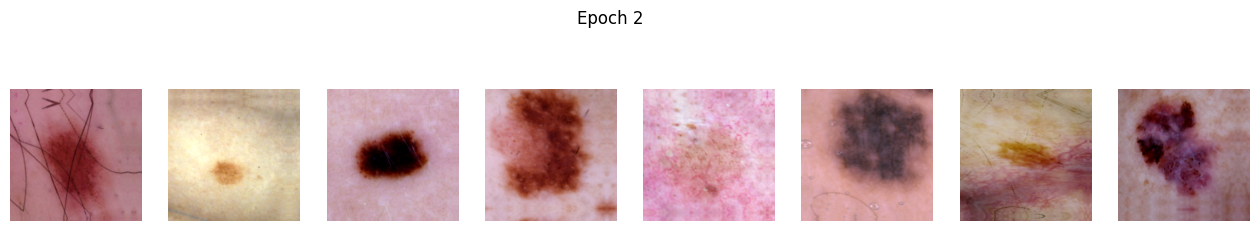

In [ ]:
# grab 1 batch of 64 images (x) and their 64 labels (y)
for x, y in train_ds.take(1):
    print('Batch shape:', x.shape, 'dtype:', x.dtype)
    print('Pixel range: [{:.1f}, {:.1f}]'.format(tf.reduce_min(x).numpy(), tf.reduce_max(x).numpy()))
    # this confirms the 1:4 ratio at batch level (but sometimes the batch can contain more/less since
      # the ratio was built on the full dataset)
    print('Label distribution in batch:', np.bincount(y.numpy().astype(int)))

# IMAGES AUGMENTATION VISUAL DEMO
# get one fixed batch (no shuffle)
images, labels = next(iter(make_dataset(train_df.head(8), training=False)))

# apply augmentation twice on the same data to see how it randomly augments images
epoch1 = data_augmentation(images, training=True)
epoch2 = data_augmentation(images, training=True)

# show Epoch 1
# 1 row, 8 images
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, img in zip(axes, epoch1):
    # this transforms the float16 image numbers to image so we can see them
    ax.imshow(img.numpy().astype("uint8"))
    ax.axis("off")
plt.suptitle("Epoch 1")
plt.show()

# show Epoch 2
fig, axes = plt.subplots(1, 8, figsize=(16, 3))
for ax, img in zip(axes, epoch2):
    ax.imshow(img.numpy().astype("uint8"))
    ax.axis("off")
plt.suptitle("Epoch 2")
plt.show()

## **6. Build EfficientNetB0 (pre-trained model preprocessing)**

In [ ]:
# EfficientNetB0 is a specialized CNN developped by Google that uses pre-trained weights to make predictions
# EfficientNetB0 is the baseline model we used it because it is the most compatible with colab even though
  # higher models are more accurate
# EfficientNetB0 is a 239 layers CNN. It is the system that takes N Dimentional tensors as input:
  # 3D tensor (224 x 244 x 3) when looking at each image by itself
  # 4D tensor (64 x 224 x 224 x 3) when looking at the whole batch
# EfficientNetB0 recognizes 1000 different things → 1000 possible classes
  # we do not want that, our output should be limited to 1:mal 0:ben

# the part of the model that makes the final outputs is called a "head"
  # and this is the only thing we need to change at this stage so the output becomes binary
  # if we include EfficientNet's weights in the update at this stage (trainable_base=True):
    # 1. this will ruin EfficientNet's carefully engineered weights (ruins the feature extractor + head produces garbage outputs)
    # 2. even if we were sure about the training, it would take much longer since we're updating millions of parameters
def build_model(input_shape=(224, 224, 3), trainable_base=False):
    inputs = layers.Input(shape=input_shape, name='input_image') # define the shape of the data
    # using a Lambda funtion to make the preprocessing () part of the model itself through tensorflow.keras.layers
    # preprocess_input(inputs) is part of the TF library for EfficientNetB0
    # it scales the images into the format EfficientNetB0 layers expect
    x = layers.Lambda(preprocess_input, name='efficientnet_preprocess')(inputs)

    # ImageNet is a massive dataset used to pre-train models like EfficientNetB0
    # include_top=false → removes the initial head to create a new one
    base = EfficientNetB0(weights='imagenet', include_top=False, input_tensor=x)
    base.trainable = trainable_base

    # new head:
    # after removing the head, the output of the base is now the last convolutional layer
    # input image: (224x224x3) - output grid(last conv layer): (7x7x1280) (by default)

    # pooling: start of the head + flattens the last conv layer 3D tensor (7x7x1280) into a 1D list of size 1280
      # to convert it into 1D: average of 7x7pixels grid(which each 1x1pixel represents 32x32pixels in the initial image) in each channel
    # each channel represents a feature
    # the downsampling happening inside efficient net is /2: (((((224 / 2) /2) / 2) / 2) / 2 )
      # at each time, each pixel in the channel starts representing more pixels: 1 → 2 → 4 → 8 → 16 → 32
    x = layers.GlobalAveragePooling2D(name='gap')(base.output)

    x = layers.Dropout(0.3, name='top_dropout1')(x) # 30% (284) of 1280 values are zeroed to prevent overfitting
    # 128 → nb of neurons
    # 1280 → input
    # for each neuron, 1280 weight
    # for the whole layer → 1280x128=163,840 connections
    # after the weighted sum ReLU:
      # if result < 0 → 0
      # if result ≥ 0 → result
    # after the Dense: x is positive due to relu + x size went from 1280 to 128
    # NOTE: in our custom head we have used relu for the activation function but originally, EfficientNetB0 uses
      # a different aftivation function named "Swish"
    x = layers.Dense(128, activation='relu', name='top_dense')(x) # produces 128 values
    x = layers.Dropout(0.4, name='top_dropout2')(x) # 40% (51) of 128 are zeroed to prevent overfitting

    # the actual new head
    # sigmoid → classifies the output as either 0 or 1
    # sigmoid(x) = 1 / (1 + e^(-x))
    output = layers.Dense(1, activation='sigmoid', dtype='float32', name='predictions')(x)

    model = Model(inputs=inputs, outputs=output)
    return model, base

# model → model with new head
# base_model → beheaded model
model, base_model = build_model(trainable_base=False)
print('Total params:', model.count_params())
# trainable params are the parameters that make the head of the model since the other parameters are freezed
print('Trainable params (phase 1):', sum(tf.size(v).numpy() for v in model.trainable_variables))

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Total params: 4213668
Trainable params (phase 1): 164097


## **7. Focal Loss + Label Smoothing**



In [ ]:
def binary_focal_loss(gamma=3.0, alpha=0.40, label_smoothing=0.05):
    def loss_fn(y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)

        # if y_true[1]=1.0 → is_positive[1]=True
        is_positive = tf.equal(y_true, 1.0)

        # Label Smoothing:
        # this transforms 0 or 1 into smaller values
        # instead of telling the model 100% mel or 0% ben → 97.5% mel or 2.5% ben → prevents overfitting
        y_true_s = y_true * (1.0 - label_smoothing) + 0.5 * label_smoothing

        # this adds a tiny value (epsilon) to ensure the prediction is always something like 0.0000001, keeping the math safe
        epsilon = tf.keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)

        # y_true → 0     y_pred → 0.1     pt=1-0.1=0.9
        # y_true → 1     y_pred → 0.9     pt=0.9
        pt = tf.where(is_positive, y_pred, 1.0 - y_pred)

        # used for increasing the melanoma weight
        alpha_t = tf.where(is_positive, alpha, 1.0 - alpha)

        # if the AI is very confident in a correct answer (pt is high), then (1−p)
          # is tiny. Squaring that tiny number by gamma makes it almost zero
        # this makes the model ignore the loss from easy cases and only pays attention to cases where (1-pt) is high
        focal_weight = alpha_t * tf.pow(1.0 - pt, gamma)

        # binary cross entropy: calculates the distance between y_pred & y_true_s
        bce = -(y_true_s * tf.math.log(y_pred) + (1.0 - y_true_s) * tf.math.log(1.0 - y_pred))
        # takes the mean of the focal loss of the batch
        return tf.reduce_mean(focal_weight * bce)
    return loss_fn

## **8. Phase 1: Train the Head (base frozen)**

In [ ]:
model.compile(
    # the optimizer decides how to adjust the weights to be less wrong next time
    # learning_rate = 0.001 is fast learning because we are only training the new head
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss=binary_focal_loss(gamma=2.0, alpha=0.25, label_smoothing=0.05),
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
    ]
)

callbacks_phase1 = [
    EarlyStopping(
        monitor='val_auc',
        patience=5, # if AUC doesnt improve for 5 epochs, training stops to prevent overfitting
        restore_best_weights=True, # after stopping, it reverts to the best version of the model
        mode='max', # means a higher nb of the monitor (val_auc) the better
        verbose=1 # to display updates during training
    ),
    ModelCheckpoint(
        filepath=str(MODEL_DIR / 'phase1_best.keras'),
        monitor='val_auc',
        save_best_only=True, # only overwrites the file if the model achieves a new "record high" Validation AUC
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_auc',
        # factor=0.5 / patience=2: if the AUC gets "stuck" for 2 epochs, it cuts the learning rate in half
          # (e.g., from 0.001 to 0.0005) to help the model find a better
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        mode='max',
        verbose=1
    )
]

# MODEL TRAINING
history1 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=callbacks_phase1,
    # missing a melanoma (1) is 4 times worse
    class_weight={0: 1.0, 1: 4.0},
    verbose=1
)
print('Phase 1 complete. Best val AUC:', max(history1.history['val_auc']))

Epoch 1/15
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 3s/step - accuracy: 0.7890 - auc: 0.6603 - loss: 0.0953 - precision: 0.4552 - recall: 0.0996
Epoch 1: val_auc improved from None to 0.84699, saving model to /content/drive/MyDrive/melanoma_project/models/phase1_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/melanoma_project/models/phase1_best.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 518s 5s/step - accuracy: 0.8052 - auc: 0.7327 - loss: 0.0769 - precision: 0.5628 - recall: 0.0889 - val_accuracy: 0.8031 - val_auc: 0.8470 - val_loss: 0.0384 - val_precision: 0.7805 - val_recall: 0.1088 - learning_rate: 0.0010
Epoch 2/15
91/92 ━━━━━━━━━━━━━━━━━━━━ 3s 4s/step - accuracy: 0.8221 - auc: 0.8196 - loss: 0.0618 - precision: 0.8124 - recall: 0.1258
Epoch 2: val_auc improved from 0.84699 to 0.88016, saving model to /content/drive/MyDrive/melanoma_project/models/phase1_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/melanoma_project/models/phase1_best.keras
92/92 ━━━━━━━━━━━

## **9. Phase 2: fine-tune the top half of EfficientNet**

In [ ]:
# unlocks the entire brain so its layers could potentially be updated during training
base_model.trainable = True

n_layers = len(base_model.layers) # 239 layers (EfficientNetB0)
n_unfreeze = n_layers // 2 # unfreeze top ~50%

print(f'EfficientNet has {n_layers} layers. Unfreezing top {n_unfreeze}.')

# freeze bottom half
# [:-n_unfreeze] means freeze everything except the n_unfreeze indexes
for layer in base_model.layers[:-n_unfreeze]:
    layer.trainable = False

# freeze all BatchNorm layers
bn_count = 0 # will track how many BatchNorm layers get frozen (used only for the print statement at the end)
for layer in base_model.layers: # looping across 239 layers
    # BatchNorm normalizes activations layer-by-layer during training for speed and more accuracy
    # pattern: Input → Conv (weighted sums) → BatchNorm: normalization of the sums → Swish(activation function) → Conv..
    # Normalization Function:
    # z_hat = (z - μ_running) / sqrt(σ²_running + ε)
    # y     = γ * z_hat + β
        # z          → raw conv output (weighted sum)
        # μ_running  → mean saved from ImageNet training      [FROZEN]
        # σ_running  → std saved from ImageNet training       [FROZEN]
        # ε          → small constant (~1e-5) prevents /0
        # γ, β       → learned scale and shift                [FROZEN]
        # y          → normalized + rescaled value passed to Swish
    # this layer is frozen to keep the mean & std computed when EfficientNet's original training on ImageNet was done
      # so that the model still knows what it's doing
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
        bn_count += 1
print(f'Froze {bn_count} BatchNorm layers (kept in inference mode).')

trainable_count = sum(tf.size(v).numpy() for v in model.trainable_variables)
print(f'Trainable params now: {trainable_count:,}')

EfficientNet has 239 layers. Unfreezing top 119.
Froze 49 BatchNorm layers (kept in inference mode).
Trainable params now: 3,829,161


In [ ]:
# recompile with very low learning_rate (0.00001) to "fine-tune" the delicate pre-trained weights without ruining them
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
    loss=binary_focal_loss(gamma=2.0, alpha=0.25, label_smoothing=0.05),
    metrics=[
        'accuracy',
        tf.keras.metrics.AUC(name='auc'),
        tf.keras.metrics.Recall(name='recall'),
        tf.keras.metrics.Precision(name='precision'),
    ]
)

callbacks_phase2 = [
    EarlyStopping(
        monitor='val_auc',
        patience=6,
        restore_best_weights=True,
        mode='max',
        verbose=1
    ),
    ModelCheckpoint(
        filepath=str(MODEL_DIR / 'phase2_best.keras'),
        monitor='val_auc',
        save_best_only=True,
        mode='max',
        verbose=1
    ),
    ReduceLROnPlateau(
        monitor='val_auc',
        factor=0.3,
        patience=3,
        min_lr=1e-7,
        mode='max',
        verbose=1
    )
]

# now 'model' is the trained EfficientNet
history2 = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks_phase2,
    class_weight={0: 1.0, 1: 4.0},
    verbose=1
)
print('Phase 2 complete. Best val AUC:', max(history2.history['val_auc']))

Epoch 1/25
92/92 ━━━━━━━━━━━━━━━━━━━━ 0s 4s/step - accuracy: 0.8257 - auc: 0.8538 - loss: 0.0575 - precision: 0.8598 - recall: 0.1352
Epoch 1: val_auc improved from None to 0.89780, saving model to /content/drive/MyDrive/melanoma_project/models/phase2_best.keras

Epoch 1: finished saving model to /content/drive/MyDrive/melanoma_project/models/phase2_best.keras
92/92 ━━━━━━━━━━━━━━━━━━━━ 562s 5s/step - accuracy: 0.8253 - auc: 0.8624 - loss: 0.0567 - precision: 0.8465 - recall: 0.1477 - val_accuracy: 0.8132 - val_auc: 0.8978 - val_loss: 0.0330 - val_precision: 0.9302 - val_recall: 0.1361 - learning_rate: 1.0000e-05
Epoch 2/25
91/92 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step - accuracy: 0.8350 - auc: 0.8653 - loss: 0.0549 - precision: 0.8249 - recall: 0.1691
Epoch 2: val_auc improved from 0.89780 to 0.89868, saving model to /content/drive/MyDrive/melanoma_project/models/phase2_best.keras

Epoch 2: finished saving model to /content/drive/MyDrive/melanoma_project/models/phase2_best.keras
92/92 ━━━━━━━

## **10. Training curves**

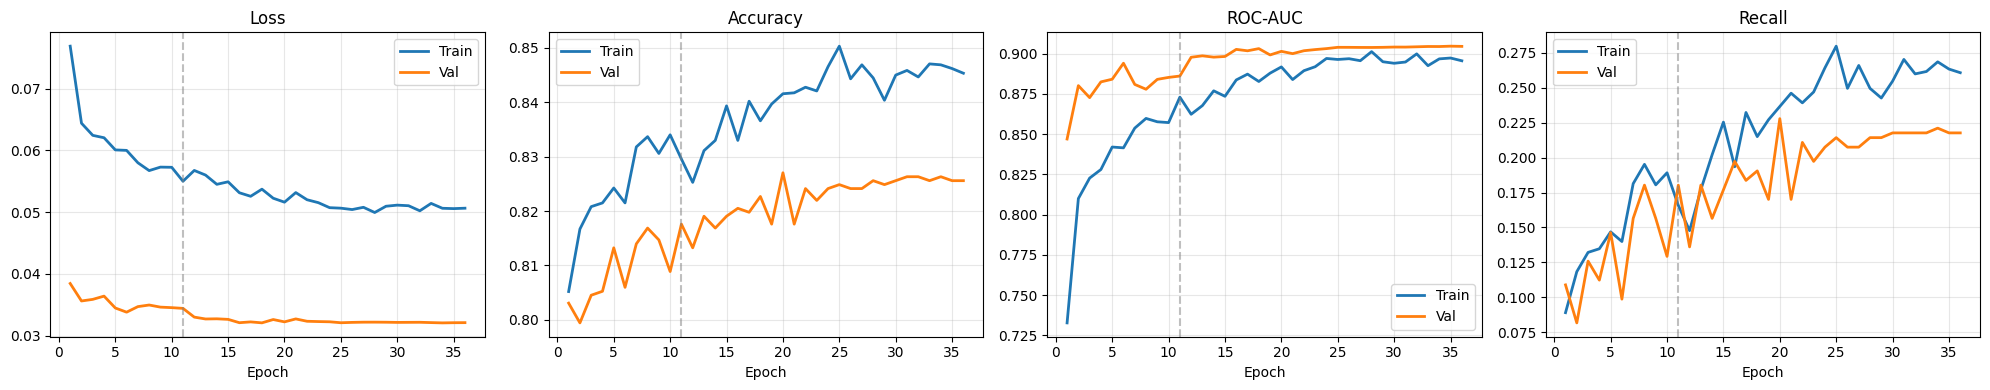

In [ ]:
def plot_history(h1, h2=None): # takes both history from phase1 & phase2
    # concatenates the metric values from both histories into one continuous list
      # to show the full timeline
    # h1.history is a dictionnary that looks like this:
    #   {
    #     'loss':         [0.8, 0.6, 0.4, ...],  # one value per epoch
    #     'val_loss':     [0.9, 0.7, 0.5, ...],
    #     'accuracy':     [0.6, 0.7, 0.8, ...],
    #     'val_accuracy': [0.5, 0.6, 0.7, ...]
    #   }
    # when merge() is called, it gets the list specific to the key given and concatenates it to the hist2
    def merge(key):
        v = h1.history.get(key, [])
        if h2:
            v = v + h2.history.get(key, [])
        return v

    epochs = range(1, len(merge('loss')) + 1)
    fig, axes = plt.subplots(1, 4, figsize=(20, 4))

    # axes are the 4 plots created
    # each tuple ('loss', 'val_loss') is the (train_metric_name, val_metric_name)
    # ['Loss', 'Accuracy', 'ROC-AUC', 'Recall']: for each axe display its title
    for ax, metric, title in zip(
      axes,
      [('loss', 'val_loss'), ('accuracy', 'val_accuracy'), ('auc', 'val_auc'), ('recall', 'val_recall')],
      ['Loss', 'Accuracy', 'ROC-AUC', 'Recall']
    ):
        # plots the train metric; metric[0] is 'loss' / 'accuracy' / ...
        ax.plot(epochs, merge(metric[0]), label='Train', linewidth=2)
        # plots the validation metric; metric[1] is 'val_loss' / 'val_accuracy' / ...
        ax.plot(epochs, merge(metric[1]), label='Val', linewidth=2)
        ax.set_title(title, fontsize=12)
        ax.set_xlabel('Epoch') # labels the x-axis
        ax.legend() # show train/val color legend
        ax.grid(alpha=0.3) # for grid design
        if h2:
            # this draws a vertical line where phase 2 has started
            ax.axvline(len(h1.history['loss']), color='gray', linestyle='--', alpha=0.5, label='Fine-tune start')

    plt.tight_layout()
    plt.savefig(str(MODEL_DIR / 'training_curves.png'), dpi=150)
    plt.show()

plot_history(history1, history2)

## **11. Evaluation with Test-Time Augmentation (TTA)**

In [30]:
def predict_with_tta(model, df, n_augments=5):
    # extract filepaths and labels to numpy arrays
    paths = df['filepath'].astype(str).values
    labels = df['label'].astype('float32').values

    # creating the base dataset with no augmentation
    # from_tensor_slices() wraps paths+labels into a TF dataset
    base_ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    # read each image, decode JPEG, resize, normalize
    base_ds = base_ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
    # groups images into batches of 64
    base_ds = base_ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

    # original predictions
    print('Predicting on original images...')
    # puts all predictions of each image in a 1D array
    preds_sum = model.predict(base_ds, verbose=1).ravel()

    # augmented predictions
    for i in range(n_augments):
        print(f'TTA pass {i+1}/{n_augments}...')
        ds = tf.data.Dataset.from_tensor_slices((paths, labels))
        ds = ds.map(decode_image, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.batch(BATCH_SIZE)
        ds = ds.map(apply_augmentation, num_parallel_calls=tf.data.AUTOTUNE)
        ds = ds.prefetch(tf.data.AUTOTUNE) # for computation speed
        # in total we have 6 predictions (1 original + 5 augmented) on the same images
        # list1 + list2 = [list1[0] + list2[0], ...]
        preds_sum = preds_sum + model.predict(ds, verbose=0).ravel()
    # getting the average
    return preds_sum / (n_augments + 1), labels


# model → trained EfficientNetB0
# test_df → test dataframe
# 5 augmented passes to run
y_prob, y_true = predict_with_tta(model, test_df, n_augments=5)

# default threshold = 0.5
# if y_prob greater or equal → 1(mel) else → 0
y_pred_default = (y_prob >= 0.5).astype(int)

# roc_auc needs probablities that's why we don't use the threshold values
roc_auc = roc_auc_score(y_true, y_prob)
acc_default = (y_pred_default == y_true).mean()
print(f'\nTest results @ threshold 0.50 (with TTA)') # TTA has changed the y_prob (total/6)
print(f'ROC-AUC : {roc_auc:.4f}')
print(f'Accuracy: {acc_default:.4f}')
print(classification_report(y_true, y_pred_default, target_names=['benign', 'melanoma']))

Predicting on original images...
20/20 ━━━━━━━━━━━━━━━━━━━━ 51s 3s/step
TTA pass 1/5...
TTA pass 2/5...
TTA pass 3/5...
TTA pass 4/5...
TTA pass 5/5...

Test results @ threshold 0.50 (with TTA)
ROC-AUC : 0.8831
Accuracy: 0.8360
              precision    recall  f1-score   support

      benign       0.84      0.99      0.91      1026
    melanoma       0.81      0.18      0.30       242

    accuracy                           0.84      1268
   macro avg       0.83      0.59      0.60      1268
weighted avg       0.83      0.84      0.79      1268



### **12. Threshold Tuning**

In [29]:
thresholds = np.arange(0.1, 0.9, 0.025) # (0.100, 0.125, 0.150 → 0.900)
results = []
for t in thresholds:
    preds = (y_prob >= t).astype(int)
    results.append({
        'threshold' : round(t, 3),
        'recall_mel': recall_score(y_true, preds),
        'precision' : precision_score(y_true, preds, zero_division=0),
        'f1'        : f1_score(y_true, preds, zero_division=0),
        'accuracy'  : (preds == y_true).mean()
    })

thresh_df = pd.DataFrame(results)

# getting the best f1 threshold
# locating the index of the highest f1 and getting the threshold of this row
best_f1_thresh = thresh_df.loc[thresh_df['f1'].idxmax(), 'threshold']

# getting the best accuracy threshold
best_acc_thresh = thresh_df.loc[thresh_df['accuracy'].idxmax(), 'threshold']

# if recall ≥ 0.85 (clinically better) and f1 is the best
# keep only the rows where recall_mel greater or equal 0.85
safe = thresh_df[thresh_df['recall_mel'] >= 0.85]
# find the highest f1 score, but if no thresholds achived 85% recall_mel → len(safe) → clinical_thresh = 0.3
clinical_thresh = safe.loc[safe['f1'].idxmax(), 'threshold'] if len(safe) else 0.3

print(thresh_df.to_string(index=False))

print(f'\nBest accuracy threshold: {best_acc_thresh}')
print(f'Best F1 threshold       : {best_f1_thresh}')
print(f'Clinical threshold (recall≥0.85)  : {clinical_thresh}')

best_thresh = clinical_thresh # since melanoma is a clinical case

 threshold  recall_mel  precision       f1  accuracy
     0.100    0.995868   0.250260 0.400000  0.429811
     0.125    0.991736   0.276180 0.432043  0.502366
     0.150    0.975207   0.302564 0.461840  0.566246
     0.175    0.962810   0.325874 0.486938  0.612776
     0.200    0.962810   0.359568 0.523596  0.665615
     0.225    0.938017   0.388699 0.549637  0.706625
     0.250    0.884298   0.408397 0.558747  0.733438
     0.275    0.847107   0.449561 0.587393  0.772871
     0.300    0.805785   0.493671 0.612245  0.805205
     0.325    0.706612   0.522936 0.601054  0.820978
     0.350    0.648760   0.554770 0.598095  0.833596
     0.375    0.574380   0.586498 0.580376  0.841483
     0.400    0.520661   0.663158 0.583333  0.858044
     0.425    0.458678   0.702532 0.555000  0.859621
     0.450    0.351240   0.752212 0.478873  0.854101
     0.475    0.260331   0.818182 0.394984  0.847792
     0.500    0.173554   0.823529 0.286689  0.835174
     0.525    0.128099   0.837838 0.222222  0.

In [33]:
y_pred_final = (y_prob >= best_thresh).astype(int)
print(f'Final results @ best threshold ({best_thresh})')
print(f'ROC-AUC  : {roc_auc:.4f}')
print(f'Accuracy : {(y_pred_final == y_true).mean():.4f}')
print(classification_report(y_true, y_pred_final, target_names=['benign', 'melanoma']))

Final results @ best threshold (0.25)
ROC-AUC  : 0.8831
Accuracy : 0.7421
              precision    recall  f1-score   support

      benign       0.96      0.71      0.82      1026
    melanoma       0.42      0.88      0.57       242

    accuracy                           0.74      1268
   macro avg       0.69      0.80      0.69      1268
weighted avg       0.86      0.74      0.77      1268



### **13. ROC Curve**

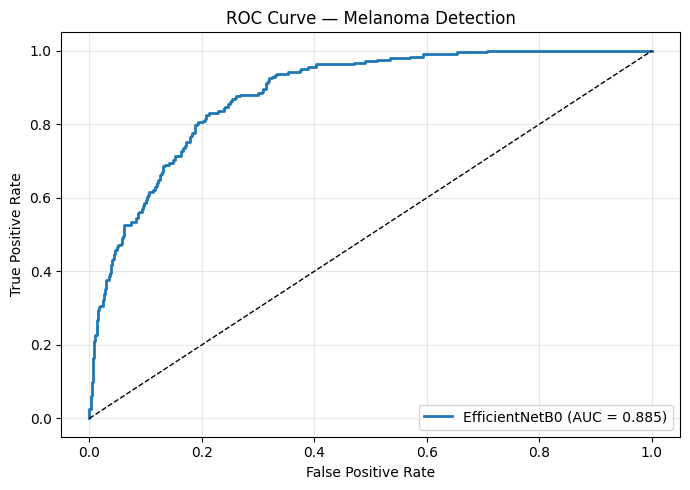

In [ ]:
fpr, tpr, _ = roc_curve(y_true, y_prob)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, lw=2, label=f'EfficientNetB0 (AUC = {roc_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', lw=1)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve — Melanoma Detection')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(str(MODEL_DIR / 'roc_curve.png'), dpi=150)
plt.show()

### **14. Confusion Matrix**

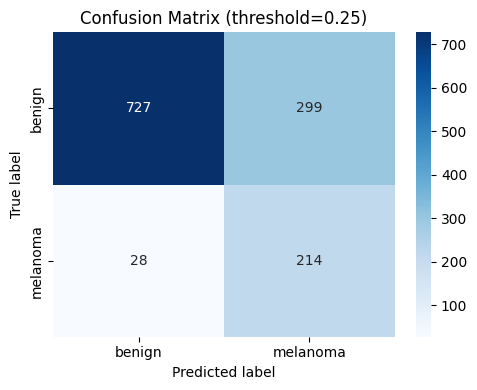

True Positives: 214
False Negatives: 28  ← minimized!
False Positives: 299
True Negatives: 727


In [35]:
cm = confusion_matrix(y_true, y_pred_final)
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['benign', 'melanoma'],
            yticklabels=['benign', 'melanoma'])
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.title(f'Confusion Matrix (threshold={best_thresh})')
plt.tight_layout()
plt.savefig(str(MODEL_DIR / 'confusion_matrix.png'), dpi=150)
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True Positives: {tp}')
print(f'False Negatives: {fn}  ← minimized!')
print(f'False Positives: {fp}')
print(f'True Negatives: {tn}')

## **15. Save final model & metadata to drive**

In [31]:
model.save(str(MODEL_DIR / 'melanoma_efficientnetb0_final.keras'))

meta = {
    'roc_auc'          : float(roc_auc),
    'best_threshold'   : float(best_thresh),
    'test_accuracy'    : float((y_pred_final == y_true).mean()),
    'img_size'         : list(IMG_SIZE),
    'batch_size'       : BATCH_SIZE,
    'train_size'       : len(train_df),
    'val_size'         : len(val_df),
    'test_size'        : len(test_df),
    'phase1_best_val_auc': float(max(history1.history['val_auc'])),
    'phase2_best_val_auc': float(max(history2.history['val_auc'])),
}
with open(MODEL_DIR / 'model_metadata.json', 'w') as f:
    json.dump(meta, f, indent=2)

print('Model and metadata saved to Drive!')
print(json.dumps(meta, indent=2))

Model and metadata saved to Drive!
{
  "roc_auc": 0.8831134309603209,
  "best_threshold": 0.25,
  "test_accuracy": 0.7334384858044164,
  "img_size": [
    224,
    224
  ],
  "batch_size": 64,
  "train_size": 5826,
  "val_size": 1376,
  "test_size": 1268,
  "phase1_best_val_auc": 0.8940815329551697,
  "phase2_best_val_auc": 0.9046832919120789
}
